
**Curso: modelos de aprendizaje**

**UNIDAD 2**


---

*   NOMBRE: Carlos Daniel Perez Noriega
*   NO CONTROL: 22111321



In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
# Ruta del archivo que voy a utilizar en la práctica
DATA_PATH = "/content/drive/MyDrive/Colab Notebooks/clase iA/data (1).csv"


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder,StandardScaler, OrdinalEncoder,FunctionTransformer

# Librerías para la canalización
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline

# Librerías para la regresión
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score, confusion_matrix, precision_score,recall_score,accuracy_score
from sklearn.decomposition import PCA

from sklearn.preprocessing import PolynomialFeatures

---

## **<font color=" #895cf9">Explica brevemente el uso de las librerias del segmento de codigo anterior, haciendo uso de la siguiente tabla</font>**

| Library | Explanation |
|----------|-------------|
| **pandas as pd** | Permite leer el archivo CSV y trabajar con los datos usando DataFrames. |
| **numpy as np** | Se usa para operaciones numéricas y para seleccionar datos de tipo numérico. |
| **matplotlib.pyplot as plt** | Sirve para crear y personalizar gráficas. |
| **seaborn as sns** | Facilita gráficas estadísticas como mapas de calor, countplots y pairplots. |
| **SimpleImputer** | Permite rellenar valores faltantes cuando sea necesario. |
| **MinMaxScaler** | Escala los datos a un rango, normalmente entre 0 y 1. |
| **OneHotEncoder / OrdinalEncoder** | Transforman variables categóricas a valores que pueda usar un modelo. |
| **StandardScaler** | Estandariza variables usando media 0 y desviación estándar 1. |
| **FunctionTransformer** | Permite aplicar una función a determinadas columnas, por ejemplo la raíz cuadrada. |
| **ColumnTransformer** | Aplica transformaciones diferentes dependiendo de las columnas seleccionadas. |
| **make_pipeline** | Une el preprocesamiento y el modelo en un mismo flujo de trabajo. |
| **LinearRegression / LogisticRegression** | Modelos de regresión lineal y clasificación mediante regresión logística. |
| **métricas de sklearn** | Sirven para evaluar los resultados del modelo, por ejemplo accuracy, precision, recall y matriz de confusión. |
| **PCA** | Reduce la cantidad de variables conservando la mayor parte de la información. |
| **PolynomialFeatures** | Genera términos polinomiales e interacciones entre variables. |

---


In [4]:
# Lectura del archivo CSV con pandas
data_df = pd.read_csv(DATA_PATH)
data_df.head()


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


# **Parte 1**. EDA

Haz que el `id` sea el índice del dataframe y efectúa una exploración inicial de los datos a través de:

In [5]:
# Convertimos la columna id en el índice del DataFrame.
# inplace=True hace que el cambio se guarde directamente en data_df.
data_df.set_index('id', inplace=True)

# Revisamos información general de los datos.
data_df.info()


<class 'pandas.core.frame.DataFrame'>
Index: 569 entries, 842302 to 92751
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   diagnosis                569 non-null    object 
 1   radius_mean              569 non-null    float64
 2   texture_mean             569 non-null    float64
 3   perimeter_mean           569 non-null    float64
 4   area_mean                569 non-null    float64
 5   smoothness_mean          569 non-null    float64
 6   compactness_mean         569 non-null    float64
 7   concavity_mean           569 non-null    float64
 8   concave points_mean      569 non-null    float64
 9   symmetry_mean            569 non-null    float64
 10  fractal_dimension_mean   569 non-null    float64
 11  radius_se                569 non-null    float64
 12  texture_se               569 non-null    float64
 13  perimeter_se             569 non-null    float64
 14  area_se                 

In [6]:
data_df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820




1a) Estadísticas descriptivas para todas las variables del dataframe.

In [7]:
# Estadísticas descriptivas de las variables numéricas
data_df.describe()


,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [8]:
# Estadísticas descriptivas de las variables categóricas
data_df.describe(include=['object'])


,diagnosis
count,569
unique,2
top,B
freq,357


1b) Valores únicos por variable para identificar posibles variables categóricas.

In [9]:
# Se hace una lista de variables numéricas y otra de categóricas.

#-----------------------------------------------------
num_cols = data_df.select_dtypes(include=np.number).columns.tolist() #para variables numericas
cat_cols = data_df.select_dtypes(exclude=np.number).columns.tolist() #para variables Categoricas
#-----------------------------------------------------

In [10]:
# Recuento de cada categoría única en las variables categóricas
for col in cat_cols:
    print(f"Columna: {col}")
    print(data_df[col].value_counts())
    print("-" * 40)


Columna: diagnosis
diagnosis
B    357
M    212
Name: count, dtype: int64
----------------------------------------


In [11]:
# También podemos revisar cuántos valores diferentes tiene cada variable categórica
for col in cat_cols:
    print(col, "->", data_df[col].nunique(), "valores únicos")


diagnosis -> 2 valores únicos


1c) Búsqueda de valores faltantes.

In [12]:
# Primero mostramos un encabezado para los resultados.
print('Número valores faltantes: ')

# Recorremos cada columna del DataFrame.
for col in data_df.columns:
  # isna() identifica los valores faltantes y sum() cuenta cuántos hay.
  valor = data_df[col].isna().sum()

  # La media de los True nos da la proporción de faltantes; multiplicamos por 100.
  porcentaje = data_df[col].isna().mean() * 100

  # Mostramos nombre de columna, cantidad y porcentaje.
  print('{}: {} | porcentaje: {:.2f}%'.format(col, valor, porcentaje))


Número valores faltantes: 
diagnosis: 0 | porcentaje: 0.00%
radius_mean: 0 | porcentaje: 0.00%
texture_mean: 0 | porcentaje: 0.00%
perimeter_mean: 0 | porcentaje: 0.00%
area_mean: 0 | porcentaje: 0.00%
smoothness_mean: 0 | porcentaje: 0.00%
compactness_mean: 0 | porcentaje: 0.00%
concavity_mean: 0 | porcentaje: 0.00%
concave points_mean: 0 | porcentaje: 0.00%
symmetry_mean: 0 | porcentaje: 0.00%
fractal_dimension_mean: 0 | porcentaje: 0.00%
radius_se: 0 | porcentaje: 0.00%
texture_se: 0 | porcentaje: 0.00%
perimeter_se: 0 | porcentaje: 0.00%
area_se: 0 | porcentaje: 0.00%
smoothness_se: 0 | porcentaje: 0.00%
compactness_se: 0 | porcentaje: 0.00%
concavity_se: 0 | porcentaje: 0.00%
concave points_se: 0 | porcentaje: 0.00%
symmetry_se: 0 | porcentaje: 0.00%
fractal_dimension_se: 0 | porcentaje: 0.00%
radius_worst: 0 | porcentaje: 0.00%
texture_worst: 0 | porcentaje: 0.00%
perimeter_worst: 0 | porcentaje: 0.00%
area_worst: 0 | porcentaje: 0.00%
smoothness_worst: 0 | porcentaje: 0.00%
comp

1d) Diagrama de barras para determinar la frecuencia de los diagnósticos (cantidad de observaciones con resultado benigno y maligno)

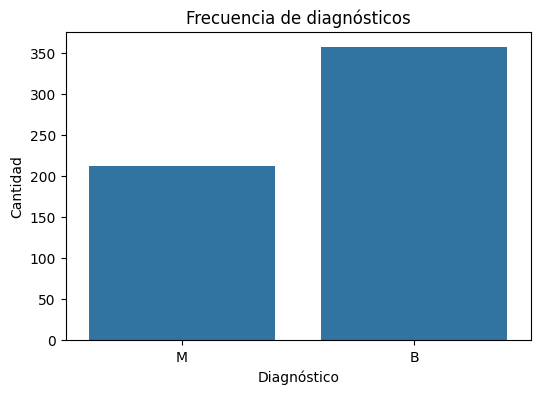

In [13]:
# Gráfica para observar cuántos diagnósticos benignos y malignos existen.
plt.figure(figsize=(6,4))
sns.countplot(data=data_df, x='diagnosis')
plt.title('Frecuencia de diagnósticos')
plt.xlabel('Diagnóstico')
plt.ylabel('Cantidad')
plt.show()


2. Como hay tres valores relacionados con la misma característica (`mean`, `se` y `worst`) es muy probable que exista multicolinealidad en el conjunto.

La multicolinealidad en regresión es una condición que ocurre cuando algunas variables predictoras están fuertemente correlacionadas entre sí, de tal manera que si se incluyen simultáneamente en un modelo, impiden explicar de manera correcta el efecto que cada una tiene sobre la variable respuesta. Existen muchas formas de analizar si hay colinealidad en los modelos, una de ellas es el alto coeficiente de correlación entre variables.

Para observar este efecto, elabora un mapa de calor que cuantifique la correlación de las variables numéricas en el dataframe.

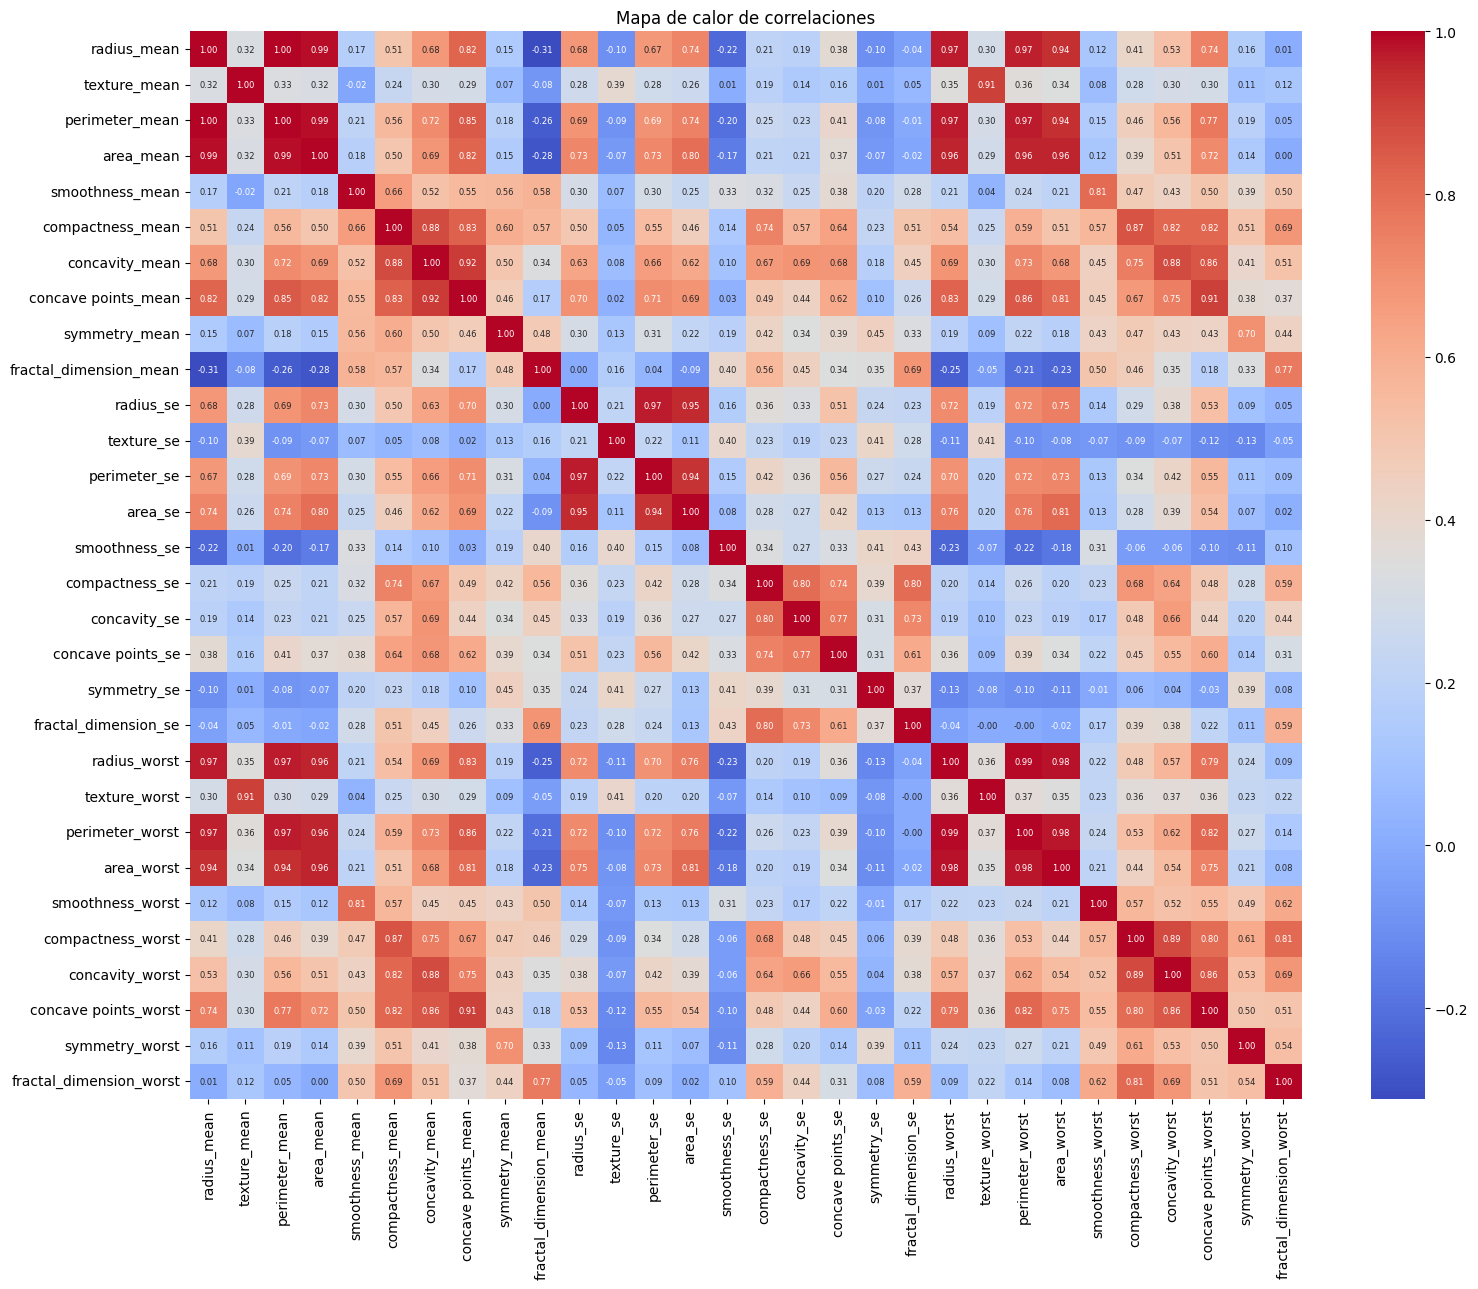

In [14]:
numeric_df = data_df.select_dtypes(include=[float, int])

# Calculamos las correlaciones entre las variables numéricas y las mostramos en un mapa de calor.
plt.figure(figsize=(16,13))
sns.heatmap(numeric_df.corr(), cmap='coolwarm', annot=True, fmt='.2f',
            annot_kws={'size': 6})
plt.title('Mapa de calor de correlaciones')
plt.tight_layout()
plt.show()


Si te fijas en los valores de correlación entre las variables `_mean` y `_worst` es evidente la multicolinearidad.

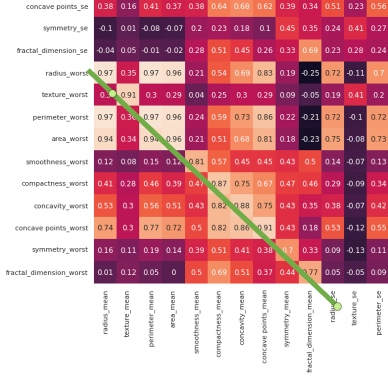

Por ejemplo, la columna `radius_mean` tiene una correlación de 0.97 con la columna `radius_worst`. Esto es algo inevitable, porque las columnas "peores" son esencialmente solo un subconjunto de las columnas "medias".

Para solucionar el problema numérico de la multicolinealidad, tradicionalmente se recurre a eliminar variables o efectuar análisis de componentes principales (PCA) con las `X`’s y usar los componentes como variables independientes en un modelo final.

Conduciremos esta actividad en esos dos sentidos.


# **Parte 2**. Modelo con eliminación de variables altamente correlacionadas  

Elimina las variables altamente correlacionadas:

3a) Ahora que sabes que las variables `_mean` y `_worst` tienen correlación alta, hay que quitar del dataframe un conjunto. Borra las columnas `_worst`.

In [15]:
# Buscamos todas las columnas cuyo nombre termina en "_worst".
worst_cols = [col for col in data_df.columns if col.endswith('_worst')]

# Las eliminamos para trabajar solamente con diagnosis, mean y se.
new_data_df = data_df.drop(columns=worst_cols)

# Nos aseguramos de mantener el resultado como DataFrame.
new_data_df = pd.DataFrame(new_data_df)

new_data_df.head()


,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_se,texture_se,perimeter_se,area_se,smoothness_se,compactness_se,concavity_se,concave points_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,1.0950,0.9053,8.589,153.40,0.006399,0.04904,0.05373,0.01587,0.03003,0.006193
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,0.5435,0.7339,3.398,74.08,0.005225,0.01308,0.01860,0.01340,0.01389,0.003532
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,0.7456,0.7869,4.585,94.03,0.006150,0.04006,0.03832,0.02058,0.02250,0.004571
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,0.4956,1.1560,3.445,27.23,0.009110,0.07458,0.05661,0.01867,0.05963,0.009208
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,0.7572,0.7813,5.438,94.44,0.011490,0.02461,0.05688,0.01885,0.01756,0.005115


En las graficas de dispersion, los patrones lineales en los diagramas de dispersion se refieren a la relacion entre dos variables que sigue una tendencia aproximadamente en linea recta, ya sea en direccion ascendente o descentende

* **Patron lineal positivo**: Si la linea se inclina hacia arriba (de izquierda a derecha), indica que hay una relacion directa entre las variables: cuando la variable aumenta, la otra tambien lo hace, es decir, CORRELACION POSITIVA

* **Patron lineal negativo**: si la linea se incluna hacia abajo (de izquierda a derecha), indica quue cuando una variable aumenta, la otra disminuye, es decir, CORRELACION NEGATIVA

* **Patron lineal perfecto**, si los puntos siguen una linea recta perfecta, la relacion entre las variables es exactamente lineal, sin desviaciones.


3b. Entre las variables `_mean`, identifica patrones lineales con diagramas de dispersión usando:

    sns.pairplot(data=nuevo_df[['radius_mean',
        'texture_mean',
        'perimeter_mean',
        'area_mean',
        'smoothness_mean',
        'compactness_mean',
        'concavity_mean',
        'concave points_mean',
        'symmetry_mean',
        'fractal_dimension_mean']])



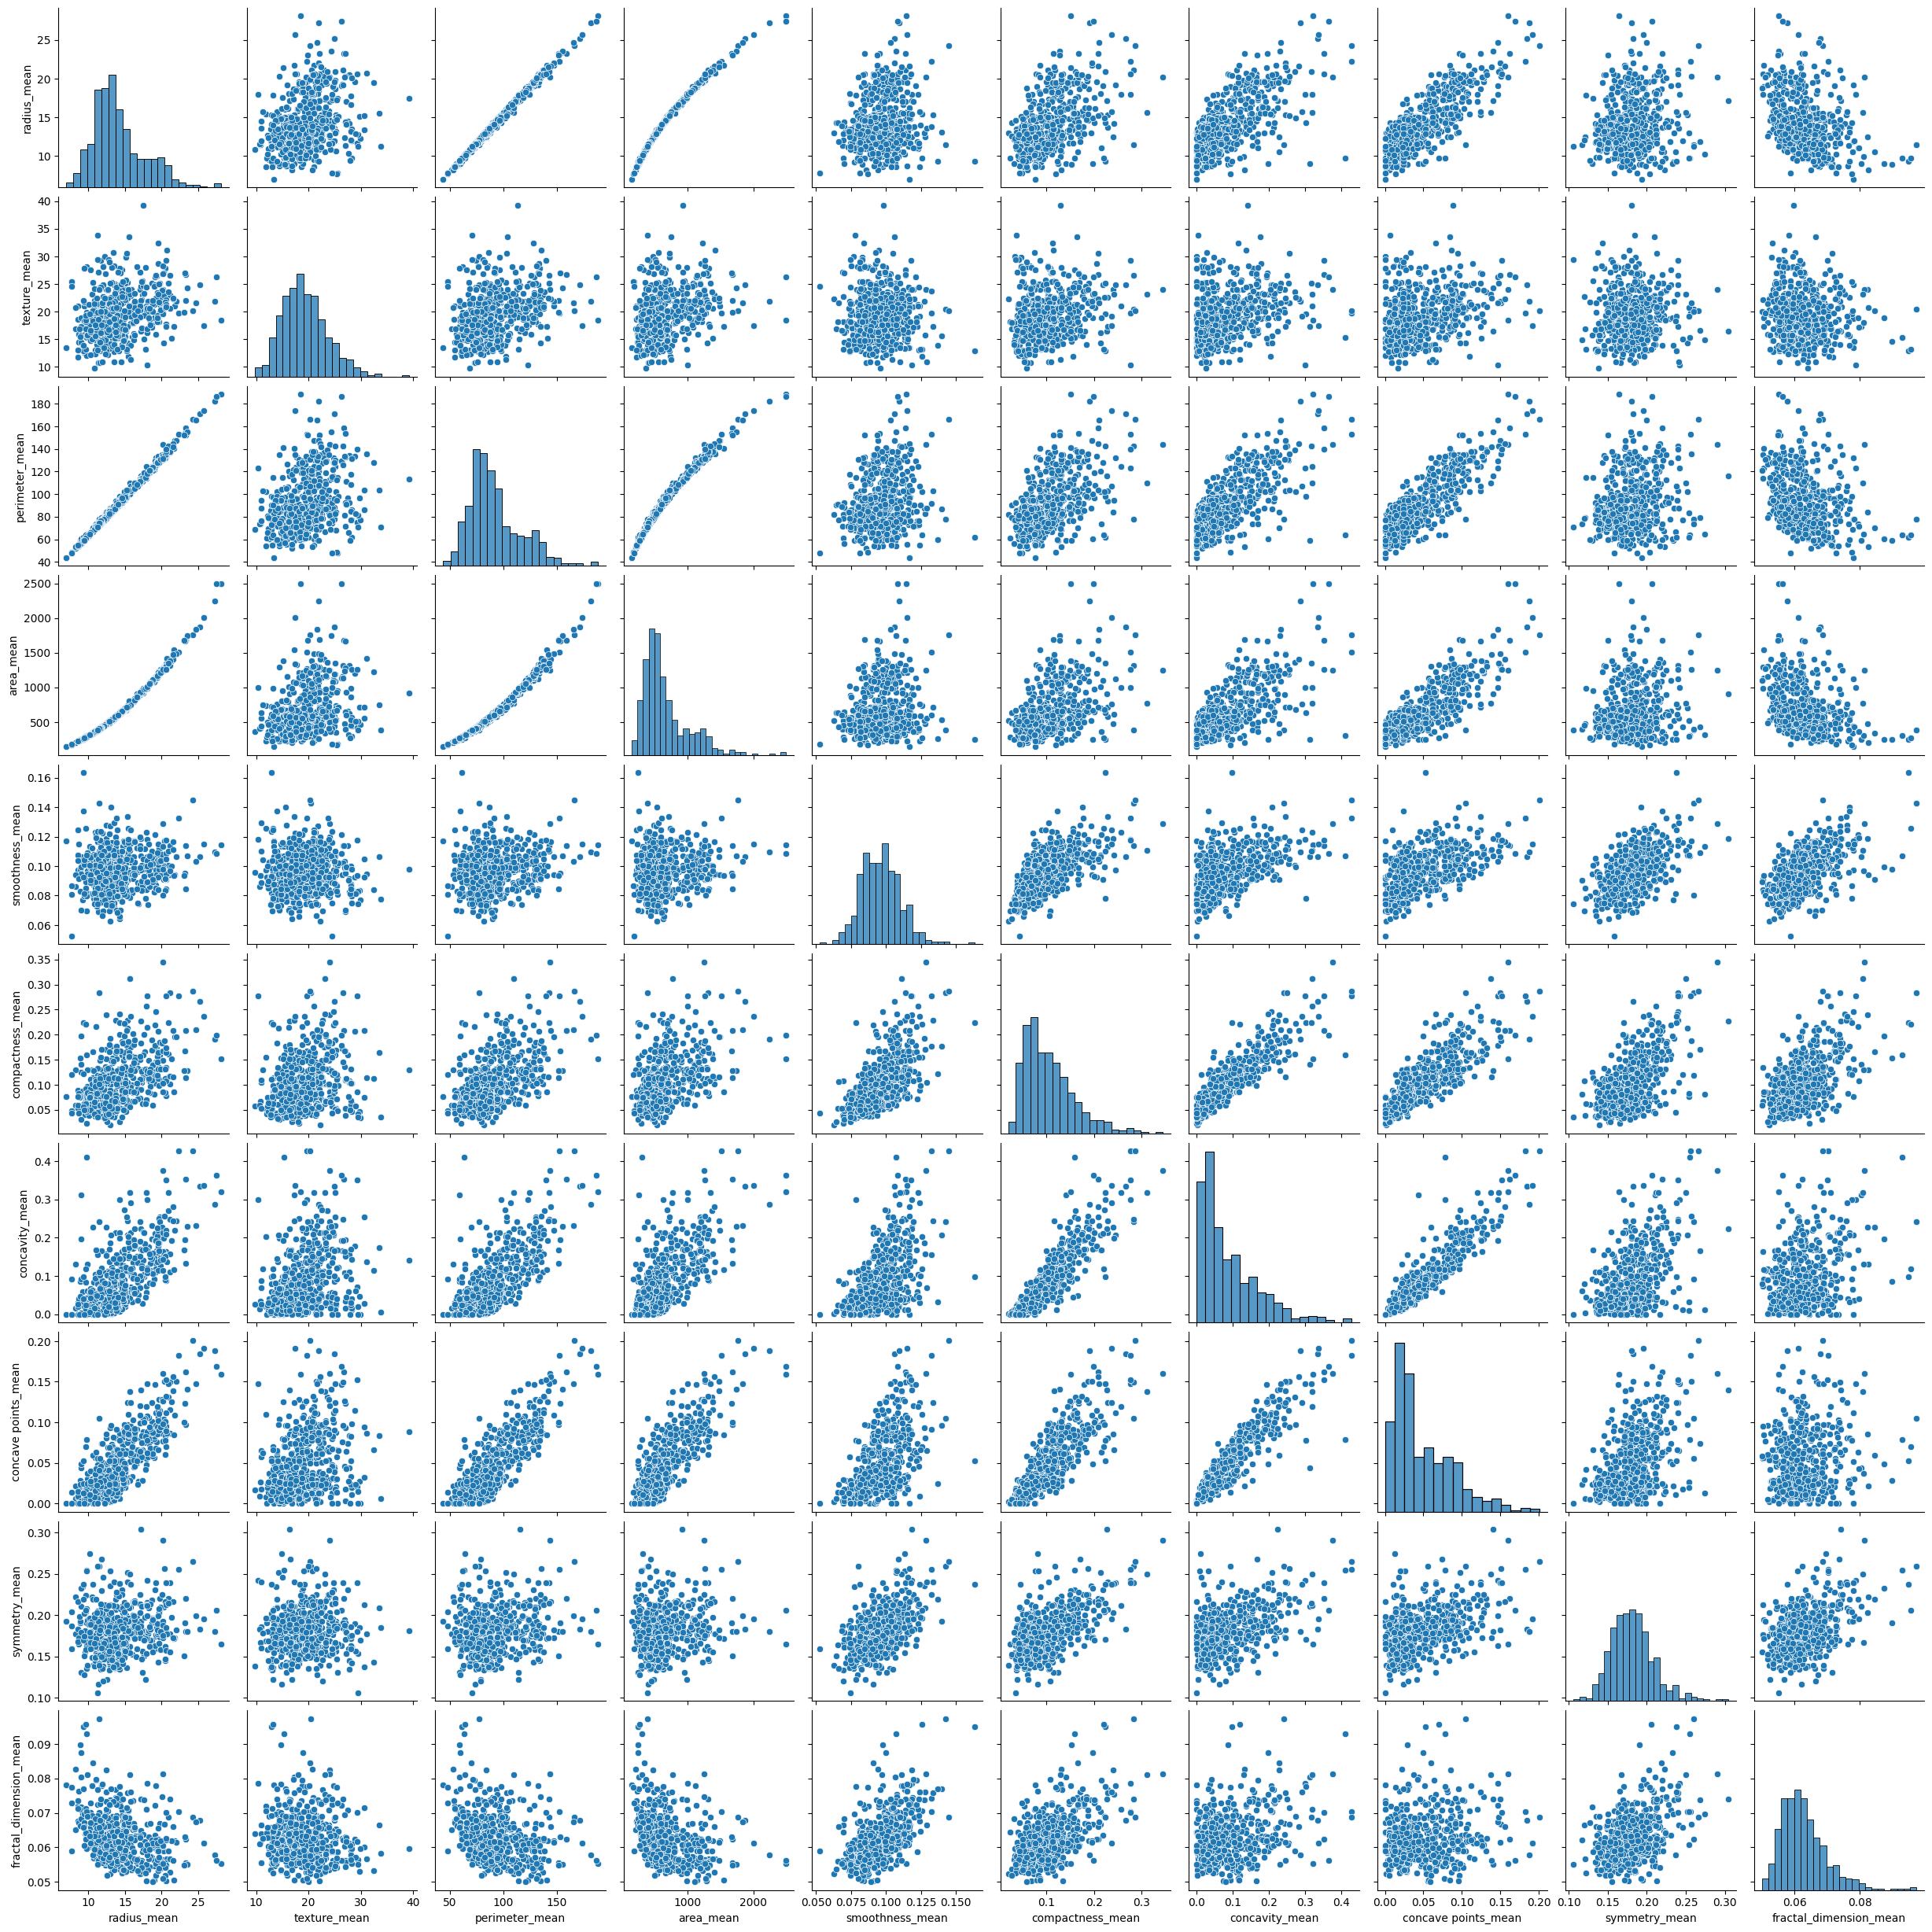

In [16]:
# Diagrama de dispersión entre las variables mean.
sns.pairplot(
    data=new_data_df[['radius_mean',
                      'texture_mean',
                      'perimeter_mean',
                      'area_mean',
                      'smoothness_mean',
                      'compactness_mean',
                      'concavity_mean',
                      'concave points_mean',
                      'symmetry_mean',
                      'fractal_dimension_mean']]
)
plt.show()


De la matriz podrás observar relaciones lineales bastante evidentes entre:


*   `radius_mean`, `perimeter_mean` y `area_mean`
*   `compactness_mean`, `concavity_mean`, `concave_points_mean`

Sabemos que el perímetro y el área de un círculo, se calculan a partir del radio. Entonces, la relación entre las primeras tres variables es muy clara para nosotros.

3c) Elabora otro mapa de calor confirmar con los valores de correlación.


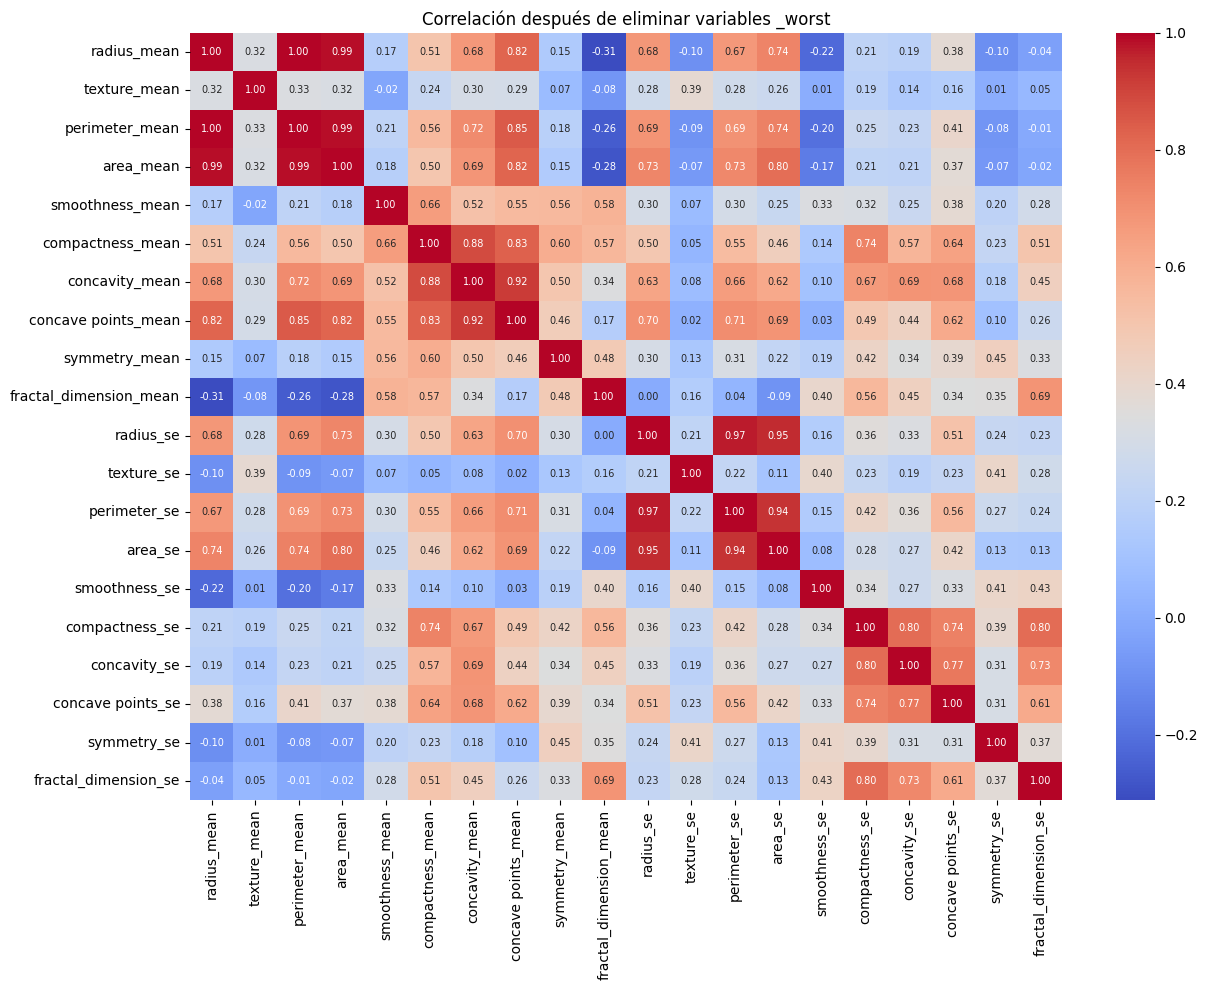

In [17]:
# Tomamos únicamente las variables numéricas del DataFrame sin las columnas _worst.
numeric_new = new_data_df.select_dtypes(include=np.number)

plt.figure(figsize=(13,10))
sns.heatmap(numeric_new.corr(), annot=True, fmt='.2f',
            cmap='coolwarm', annot_kws={'size': 7})
plt.title('Correlación después de eliminar variables _worst')
plt.tight_layout()
plt.show()


3d) Después de observar los valores, nos quedaremos con sólo una variable de cada trío: `radius_mean` y `compactness_mean`. Elimina las restantes, no sólo del conjunto `_mean`, sino también de `_se`.

In [18]:
# Se eliminan las variables redundantes de los dos grupos señalados en el enunciado.
# Nos quedamos con radius_mean y compactness_mean como representantes de esos grupos.
columnas_a_eliminar = [
    'perimeter_mean',
    'area_mean',
    'concavity_mean',
    'concave points_mean',
    'perimeter_se',
    'area_se',
    'concavity_se',
    'concave points_se'
]

# Creamos un nuevo DataFrame ya sin esas columnas.
new_data_df = pd.DataFrame(new_data_df.drop(columns=columnas_a_eliminar))

new_data_df


,diagnosis,radius_mean,texture_mean,smoothness_mean,compactness_mean,symmetry_mean,fractal_dimension_mean,radius_se,texture_se,smoothness_se,compactness_se,symmetry_se,fractal_dimension_se
id,,,,,,,,,,,,,
842302,M,17.99,10.38,0.11840,0.27760,0.2419,0.07871,1.0950,0.9053,0.006399,0.04904,0.03003,0.006193
842517,M,20.57,17.77,0.08474,0.07864,0.1812,0.05667,0.5435,0.7339,0.005225,0.01308,0.01389,0.003532
84300903,M,19.69,21.25,0.10960,0.15990,0.2069,0.05999,0.7456,0.7869,0.006150,0.04006,0.02250,0.004571
84348301,M,11.42,20.38,0.14250,0.28390,0.2597,0.09744,0.4956,1.1560,0.009110,0.07458,0.05963,0.009208
84358402,M,20.29,14.34,0.10030,0.13280,0.1809,0.05883,0.7572,0.7813,0.011490,0.02461,0.01756,0.005115
...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,0.11100,0.11590,0.1726,0.05623,1.1760,1.2560,0.010300,0.02891,0.01114,0.004239
926682,M,20.13,28.25,0.09780,0.10340,0.1752,0.05533,0.7655,2.4630,0.005769,0.02423,0.01898,0.002498
926954,M,16.60,28.08,0.08455,0.10230,0.1590,0.05648,0.4564,1.0750,0.005903,0.03731,0.01318,0.003892


Observa la distribución de las variables resultantes (deben ser 12, sin contar la columna de indice):

4a) Utilizando histogramas. Guarda en una variable (`skew_cols`) las que tengan marcado sesgo positivo. Para dar seguridad a tu selección, elige aquellas cuyo resultado de aplicar la función `skew()` sea mayor a 1.

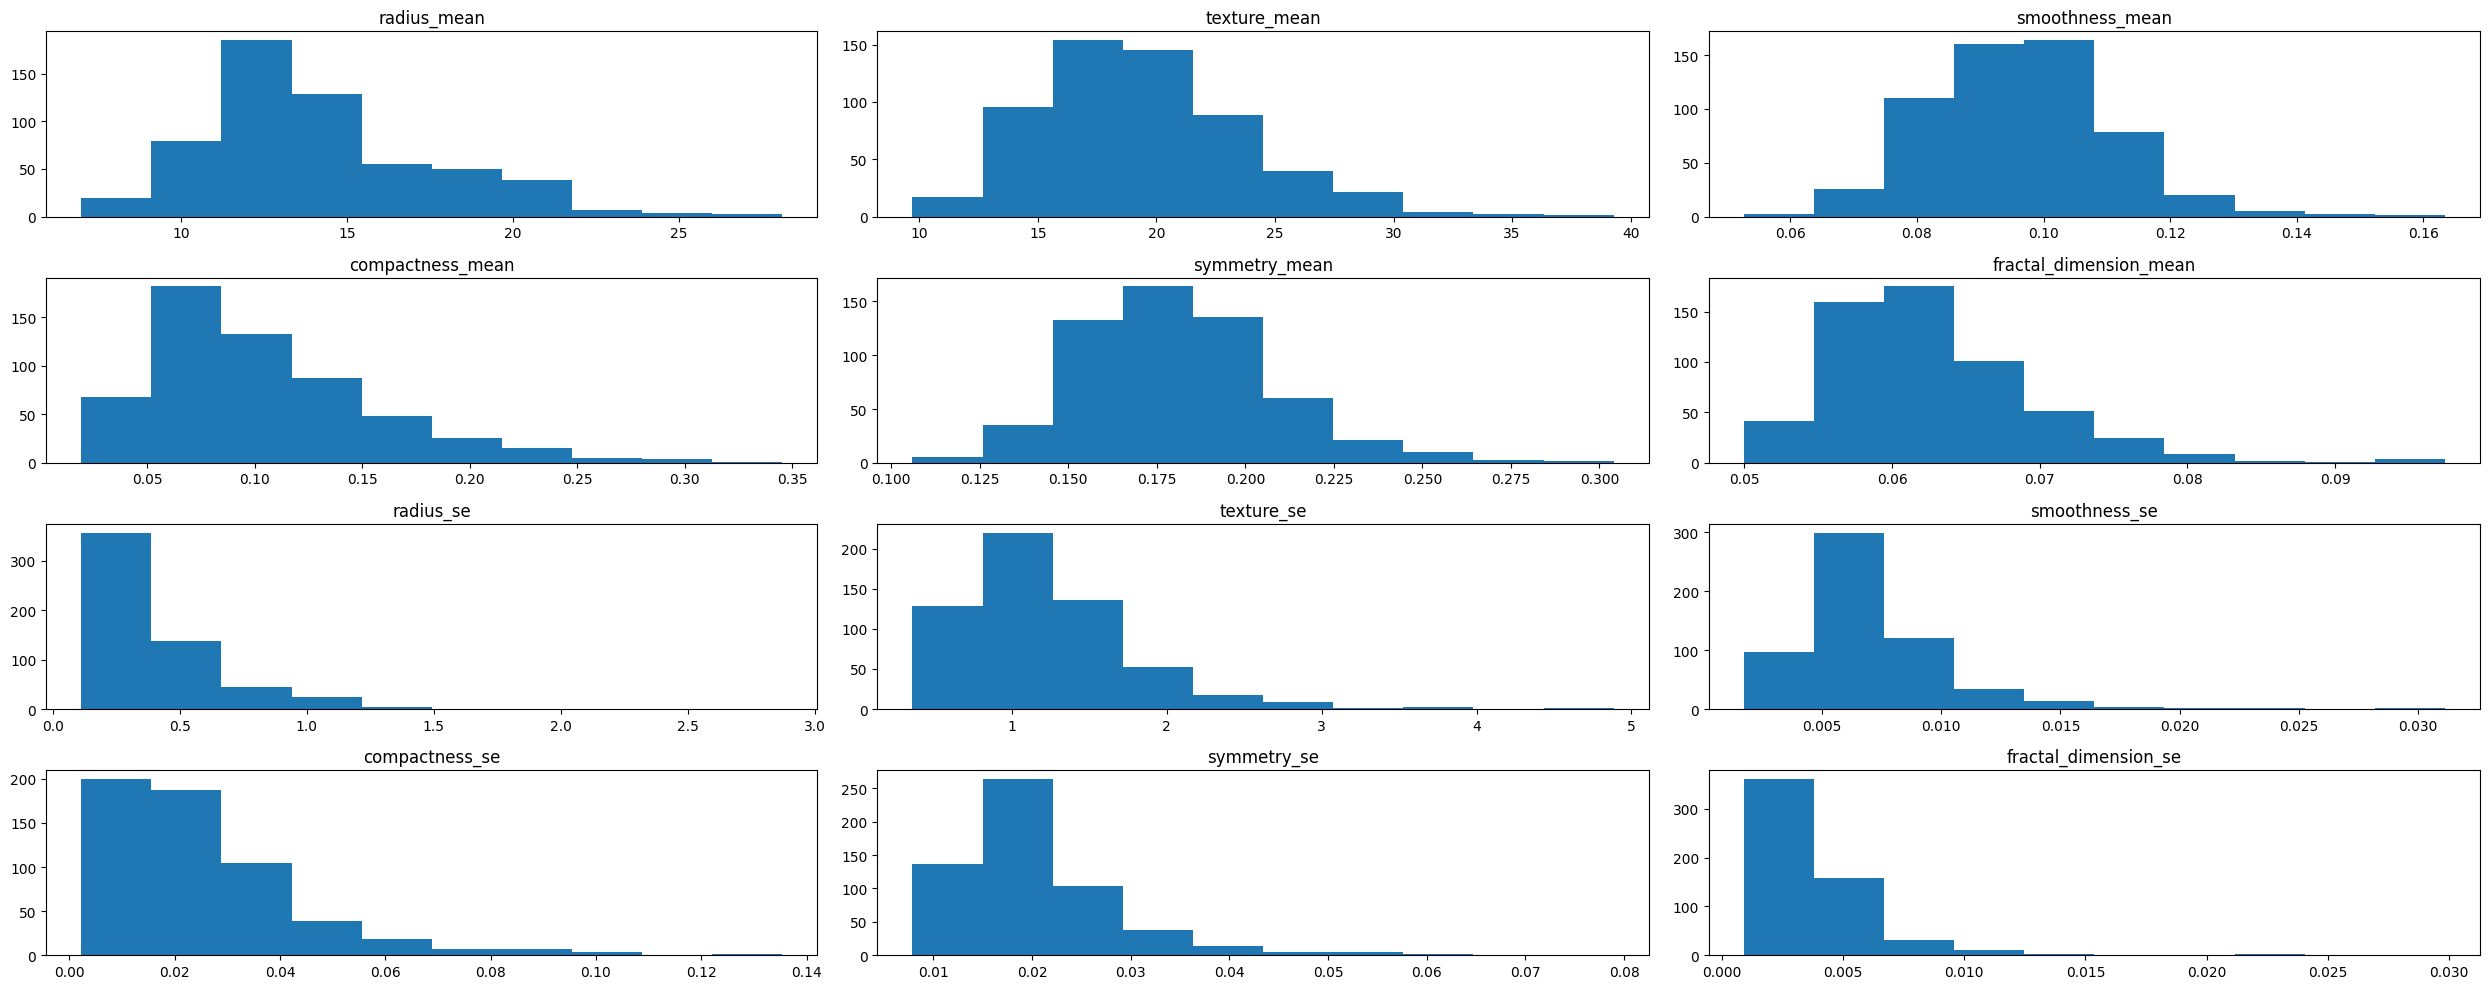

In [19]:
# DataFrame temporal donde se guardarán las variables con sesgo alto.
skew_cols_df = pd.DataFrame()

# Se crean 12 espacios para mostrar los histogramas.
fig, axes = plt.subplots(4, 3, figsize=(25,10))
axes = axes.ravel()

# Solo nos interesan las columnas numéricas.
num_cols = new_data_df.select_dtypes(include=np.number).columns.tolist()

# Recorremos cada columna junto con su espacio en la figura.
for col, ax in zip(num_cols, axes):
  ax.hist(new_data_df[col])
  ax.set(title=col, xlabel=None)

  # Si el sesgo es mayor que 1, guardamos esa variable.
  if new_data_df[col].skew() > 1:
    skew_cols_df[col] = new_data_df[col]

plt.tight_layout()

# Finalmente guardamos solo los nombres de las columnas.
skew_cols = skew_cols_df.columns.values


In [20]:
skew_cols

array(['compactness_mean', 'fractal_dimension_mean', 'radius_se',
       'texture_se', 'smoothness_se', 'compactness_se', 'symmetry_se',
       'fractal_dimension_se'], dtype=object)

4b) Dibujando box plots de todas las variables. Guarda en una variable (`scale_cols`) aquellas que no se encuentren en el intervalo [0,1]


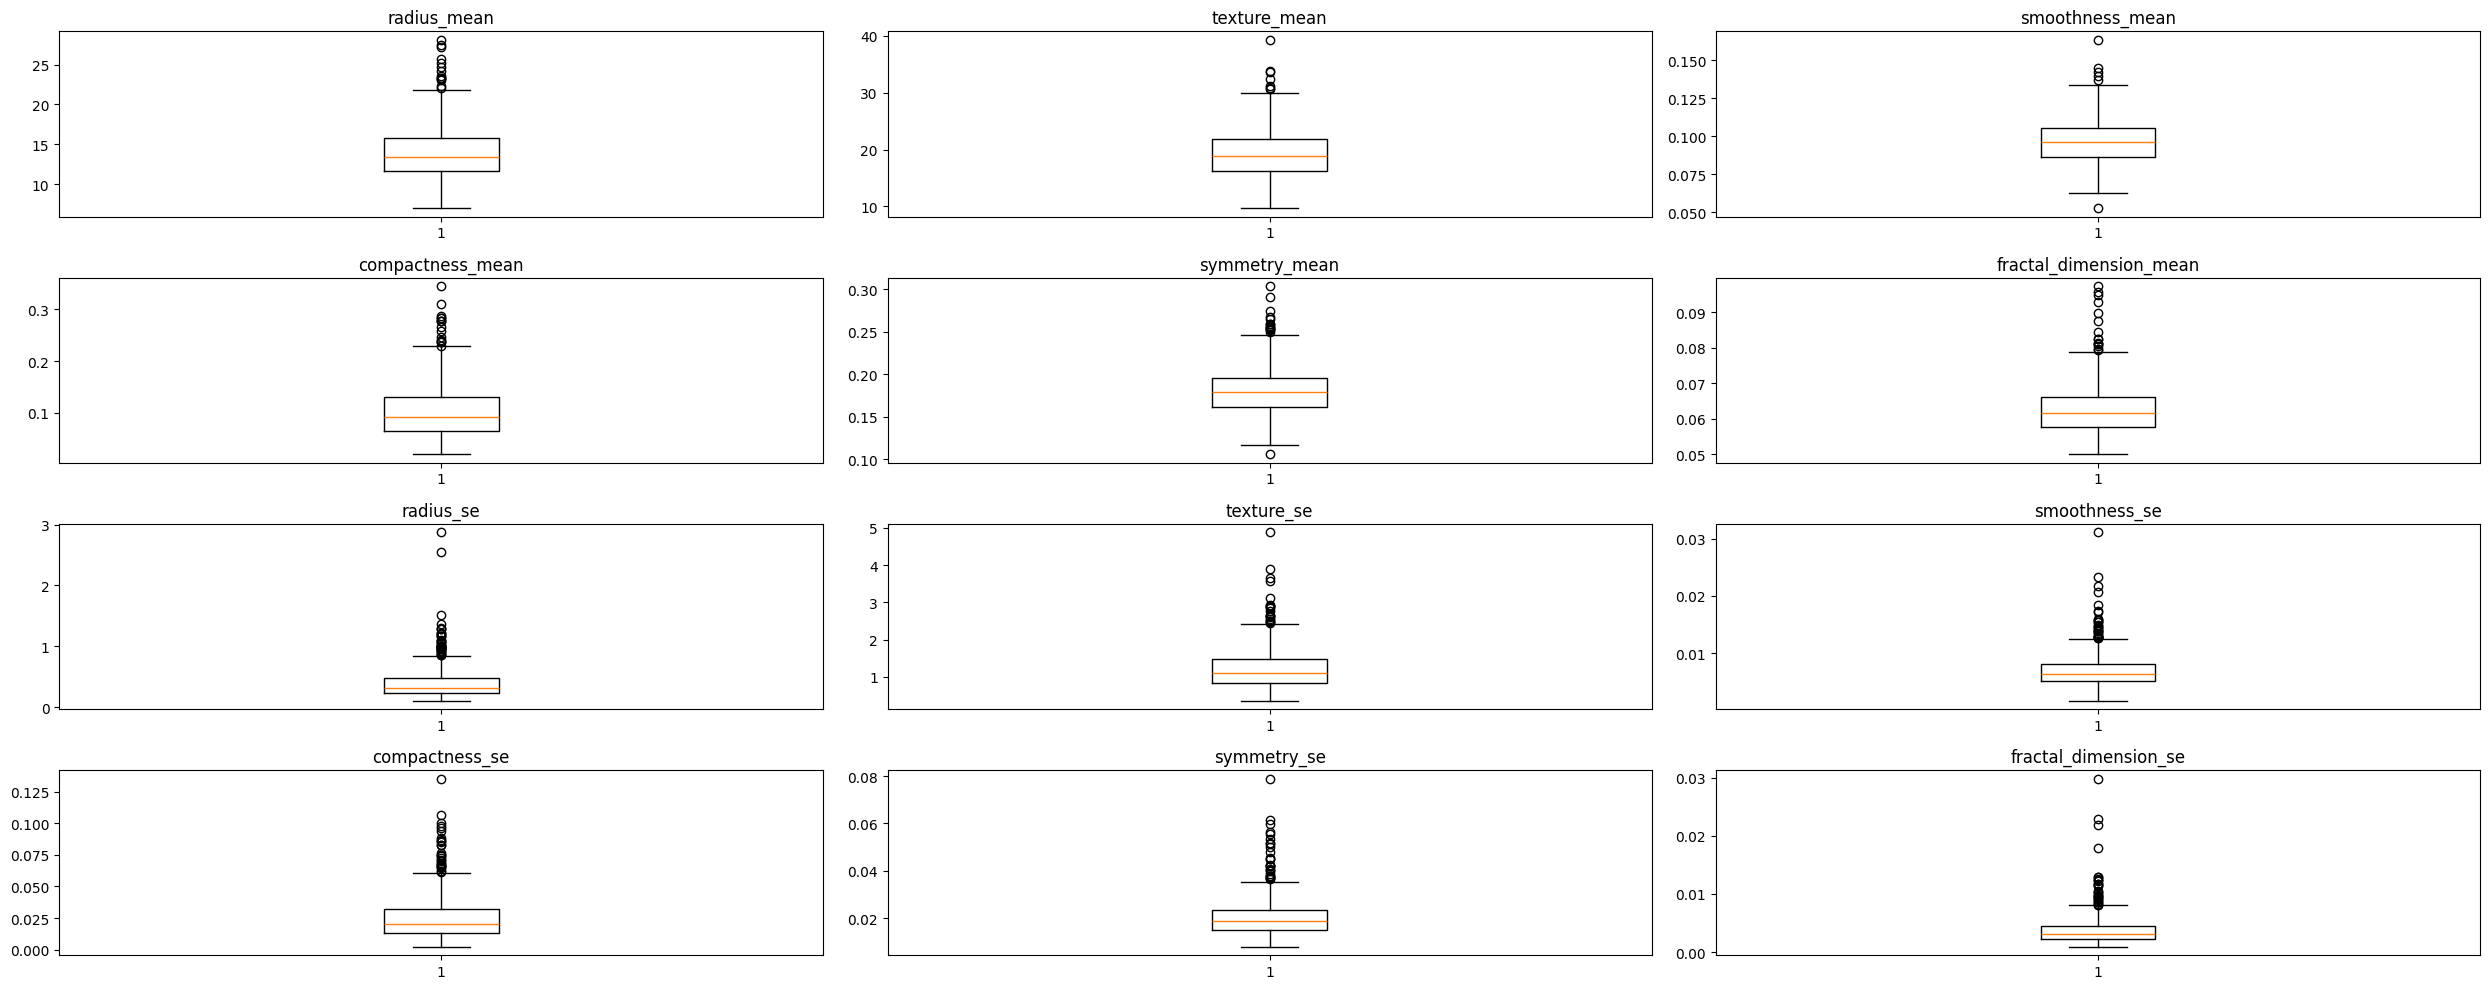

In [21]:
# DataFrame temporal para almacenar variables que necesitan escalamiento.
scale_cols_df = pd.DataFrame()

fig, axes = plt.subplots(4,3, figsize=(25,10))
axes = axes.ravel()

for col, ax in zip(num_cols, axes):
  # Dibujamos un boxplot para observar la escala de cada variable.
  ax.boxplot(new_data_df[col])
  ax.set_title(col)

  # Si algún valor está fuera de [0,1], la columna necesita escalamiento.
  if new_data_df[col].min() < 0 or new_data_df[col].max() > 1:
    scale_cols_df[col] = new_data_df[col]

plt.tight_layout()

scale_cols = scale_cols_df.columns.values


In [22]:
scale_cols

array(['radius_mean', 'texture_mean', 'radius_se', 'texture_se'],
      dtype=object)

Con todo el análisis anterior, estamos listos para generar un modelo *baseline* denominado `logr_model`. Para ello:

5a) Vuelve a leer el contenido del archivo, haz que el `id` sea el índice y separa las variables del dataframe: en `X` coloca los predictores y en `y` la variable de respuesta o salida (`diagnosis`). Divide el conjunto en entrenamiento y prueba (80:20) considerando el parámetro `random_state` con el valor de 1.

In [23]:
# Volvemos a leer el archivo original para construir el modelo desde cero.
data_df = pd.read_csv(DATA_PATH)

# Convertimos id en índice.
data_df.set_index('id', inplace=True)


In [24]:
# Se crea una copia del DataFrame para las variables de entrada.
X = data_df.copy()

# Quitamos diagnosis de X porque será nuestra variable de salida.
X.drop('diagnosis', axis=1, inplace=True)

# Variable objetivo.
y = data_df['diagnosis']


In [25]:
# Librería necesaria para dividir el conjunto de datos.
from sklearn.model_selection import train_test_split

# 80% de los datos se usan para entrenamiento y 20% para prueba.
Xtrain, Xtest, ytrain, ytest = train_test_split(
    X, y,
    test_size=0.20,
    random_state=1
)

print("Entrenamiento:", Xtrain.shape)
print("Prueba:", Xtest.shape)


Entrenamiento: (455, 30)
Prueba: (114, 30)


5b) Prepara un transformador, denominado `preprocessing`, para borrar las columnas altamente correlacionadas (las 18 variables que se determinaron en los ejercicios previos) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.

In [26]:
# Lista completa de las 18 columnas que decidimos retirar por alta correlación.
columnas_a_eliminar = [
    'radius_worst','texture_worst','perimeter_worst','area_worst',
    'smoothness_worst','compactness_worst','concavity_worst',
    'concave points_worst','symmetry_worst','fractal_dimension_worst',
    'perimeter_mean','area_mean','concavity_mean','concave points_mean',
    'perimeter_se','area_se','concavity_se','concave points_se'
]

# ColumnTransformer elimina esas columnas.
# remainder='passthrough' conserva todas las demás.
preprocessing = ColumnTransformer(
    [('num', 'drop', columnas_a_eliminar)],
    remainder='passthrough'
)


5c) Entrena el modelo `logr_model` con el transformador `preprocessing` y  regresión logística.

Como la salida `y` está en términos de las etiquetas `'B'` y `'M'`, en lugar de 0 y 1, para evaluar el modelo en el conjunto de prueba deberás especificar la clase positiva. En el caso de la matriz de confusión, indica el orden de las etiquetas con `labels=['B','M']`, porque `'B'` es la clase negativa (ésta se especifica primero) y `'M'` la positiva. Para las métricas de *recall* y *precision*, utiliza el parámetro `pos_label='M'`. Como *accuracy* ocupa la suma de ambas clases y el total de las observaciones, no requiere ninguna especificación. Si quisieras omitir estos parámetros, tendrías que sustituir `'B'` por 0 y `'M'` por 1, previo a la construcción del modelo.

In [27]:
# Creamos un pipeline: primero se eliminan las columnas y después se aplica Regresión Logística.
logr_model = make_pipeline(
    preprocessing,
    LogisticRegression(max_iter=1000)
)

# Entrenamiento.
logr_model.fit(Xtrain, ytrain)

# Predicciones con el conjunto de prueba.
predictions = logr_model.predict(Xtest)

# Evaluación del modelo.
print('matriz de confusion 1:\n',
      confusion_matrix(ytest, predictions, labels=['B','M']))
print('recall    :\t', recall_score(ytest, predictions, pos_label='M'))
print('precision :\t', precision_score(ytest, predictions, pos_label='M'))
print('accuracy  :\t', accuracy_score(ytest, predictions))


matriz de confusion 1:
 [[68  4]
 [10 32]]
recall    :	 0.7619047619047619
precision :	 0.8888888888888888
accuracy  :	 0.8771929824561403


### Interpretación del modelo 1

La matriz de confusión permite revisar en qué casos acertó y en cuáles se equivocó el modelo. La primera fila corresponde a los casos benignos y la segunda a los malignos.

En este problema me parece especialmente importante observar el **recall de la clase M**, porque un falso negativo significa que un caso maligno fue clasificado como benigno. La precisión indica qué tan confiables son las predicciones cuando el modelo dice que el diagnóstico es maligno, mientras que el accuracy muestra el porcentaje total de predicciones correctas.

Con `random_state=1`, el resultado esperado está alrededor de **87.7% de accuracy**, aunque al ejecutar el notebook la interpretación debe hacerse con los valores que aparezcan en pantalla.


Para generar un modelo `logr_model2` con transformación y escalamiento:

6a) Modifica el transformador anterior para, además del borrado de las columnas correlacionadas, aplicar la raíz cuadrada a los predictores con sesgo (previamente almacenados en `skew_cols`) y escalamiento *MinMax* a los predictores con escala mayor a 1 (previamente almacenados en `scale_cols`) Como no todos los predictores serán eliminados o transformados, asegúrate de incluir el parámetro `remainder='passthrough'`

In [28]:
# Este segundo preprocesamiento combina tres operaciones.
preprocessing2 = ColumnTransformer([
    # 1) Elimina las variables altamente correlacionadas.
    ('num0', 'drop', columnas_a_eliminar),

    # 2) Aplica raíz cuadrada a las variables con sesgo positivo.
    ('num1', FunctionTransformer(np.sqrt), skew_cols),

    # 3) Escala las variables que están fuera del intervalo [0,1].
    ('num2', MinMaxScaler(), scale_cols)
  ],
  remainder='passthrough'
)


6b) Entrena el modelo `logr_model2` con regresión logística, aplicando previamente el transformador modificado. Evalúa el modelo en el conjunto de prueba con las mismas métricas.

In [29]:
# Creamos el segundo pipeline con el nuevo preprocesamiento.
logr_model2 = make_pipeline(
    preprocessing2,
    LogisticRegression(max_iter=1000)
)

# Entrenamos el modelo.
logr_model2.fit(Xtrain, ytrain)

# Hacemos predicciones.
predictions2 = logr_model2.predict(Xtest)

# Evaluamos utilizando las mismas métricas del primer modelo.
print('matriz de confusion 2:\n',
      confusion_matrix(ytest, predictions2, labels=['B','M']))
print('recall    :\t', recall_score(ytest, predictions2, pos_label='M'))
print('precision :\t', precision_score(ytest, predictions2, pos_label='M'))
print('accuracy  :\t', accuracy_score(ytest, predictions2))


matriz de confusion 2:
 [[72  0]
 [11 31]]
recall    :	 0.7380952380952381
precision :	 1.0
accuracy  :	 0.9035087719298246


### Interpretación del modelo 2

Este modelo ya no trabaja solamente con la eliminación de variables correlacionadas. También transforma las variables con sesgo positivo y escala las que tienen magnitudes mayores a 1.

Para compararlo con el modelo anterior hay que revisar principalmente **recall, precision y accuracy**. Si el accuracy aumenta pero el recall de los casos malignos baja, no necesariamente significa que sea mejor para un problema médico, porque seguirían existiendo casos malignos que no fueron detectados.

Por eso no conviene escoger un modelo únicamente por el porcentaje general de aciertos; la matriz de confusión ayuda a ver exactamente qué tipo de error está cometiendo.


# **Conclusión de la práctica**

En esta práctica pude ver que antes de entrenar un modelo es necesario revisar bien los datos. El análisis exploratorio permitió encontrar variables muy relacionadas entre sí, por ejemplo `radius_mean`, `perimeter_mean` y `area_mean`, por lo que mantenerlas todas podía agregar información repetida.

Después de eliminar variables correlacionadas, también se revisó la distribución de los datos. Las variables con sesgo mayor a 1 se transformaron con raíz cuadrada y las que estaban fuera del rango de 0 a 1 se escalaron con `MinMaxScaler`.

Finalmente se compararon dos modelos de regresión logística. El primero funciona como una referencia y el segundo incluye más preprocesamiento. Lo que me quedó de la práctica es que no basta con fijarse solamente en el accuracy; en un caso de diagnóstico también es importante revisar el recall y los falsos negativos, porque esos errores tienen mayor impacto.
